### Import the Libraries and set the style for Plotting

In [108]:
import torch, torch.nn as nn
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [109]:
plt.style.use('dark_background')

### Load the dataset

##### Training set

- Use only $P_1,P_3,Q_1,Q_2$ as inputs. This makes leak detection genuinely uncertain rather than almost directly determined by mass balance, i.e. the amount of fluid entering a pipe/network must equal the amount leaving it **plus any fluid lost through a leak**.
$$
Q_{\text{in}} = Q_{\text{out}} + Q_{\text{leak}}
$$
- we standardize the variables so that one of them doesn't end up dominating over others when computing the gradients
$$
Z=\frac{X_{\text{train}}-\mu_{\text{train}}}{\sigma_{\text{train}}}
$$
this makes sure that all variables have $\text{mean}=0$ and $\text{standard deviation}=1$

In [ ]:
train_dataset = pd.read_csv(r"C:\Data\Project\Phase 0 (Toy)\toy_dataset(train).csv")
X_train = train_dataset.iloc[:, :4].fillna(0)
train_std = X_train.std()
train_mean = X_train.mean()
X_train = (X_train - train_mean) / train_std
x_train = torch.tensor(X_train.values, dtype=torch.float32)
train_dataset.head()

,P1,P3,Q1,Q2,demand_j1,demand_j3,reservoir_head,leak_node,emitter_coeff,y
0,33.228275,33.228060,0.001388,0.000586,12.720387,9.282277,109.020164,NaN,0.00000,0
1,29.376793,29.376392,0.001745,0.000814,14.753694,12.899649,96.385915,NaN,0.00000,0
2,29.334848,29.334427,0.001289,0.000839,7.142121,12.212599,96.246001,3.0,0.16765,1
3,29.228388,29.228033,0.001108,0.000764,5.445547,12.113554,95.895972,NaN,0.00000,0
4,34.409380,34.409065,0.001492,0.000721,12.222844,11.422517,112.895697,NaN,0.00000,0


##### Test set

The training set is what the model learns from. The test data must then be put into the same coordinate system before being given to the trained model. so we will standardize the test set using the mean and variance of the training set and not the test set.
$$
Z=\frac{X_{\text{test}}-\mu_{\text{train}}}{\sigma_{\text{train}}}
$$

In [ ]:
test_dataset = pd.read_csv(r"C:\Data\Project\Phase 0 (Toy)\toy_dataset(test).csv")
X_test = test_dataset.iloc[:, :4].fillna(0)
X_test = (X_test - train_mean) / train_std
x_test = torch.tensor(X_test.values, dtype=torch.float32)
test_dataset.head()

,P1,P3,Q1,Q2,demand_j1,demand_j3,reservoir_head,leak_node,emitter_coeff,y
0,33.159645,33.159470,0.001152,0.000523,9.966398,8.293912,108.793980,NaN,0.000000,0
1,29.405872,29.405653,0.001204,0.000593,9.690941,9.143344,96.478664,3.0,0.039315,1
2,31.871284,31.871056,0.001313,0.000603,11.251181,9.381307,104.567752,3.0,0.027109,1
3,27.439898,27.439758,0.000912,0.000464,7.105775,7.354601,90.027532,NaN,0.000000,0
4,29.852210,29.852040,0.001734,0.000513,11.475031,8.132765,97.945624,1.0,1.210077,1


### Create the Deep Neural Network

In [126]:
def DNN(D_i, D_k, D_o):
    arch = [D_i] + D_k + [D_o]
    layers = []
    for i in range(len(arch) - 1):
        layers.append(nn.Linear(arch[i], arch[i+1]))
        if i < len(arch) - 2:
            layers.append(nn.ReLU())
    model = nn.Sequential(*layers)
    return model

def network_output(x, model):
    return model(x)

### Initialize network parameters (*He initialization*)

In [127]:
def initialize_parameters(model):
    for index, layer in enumerate(model):
        if index % 2 == 0:
            nn.init.kaiming_normal_(layer.weight)
            layer.bias.data.fill_(0.0)
        print("Initializing Layer")

### Declare the Model

In [ ]:
network = DNN(4, [50, 50], 1)
initialize_parameters(network)

Initializing Layer
Initializing Layer
Initializing Layer
Initializing Layer
Initializing Layer


### Define Loss Function

In [146]:
def Binary_Cross_Entropy_Loss(x_train, network, y_train):
    logits = network_output(x_train, network)
    loss = torch.binary_cross_entropy_with_logits(torch.squeeze(logits), y_train)
    return torch.mean(loss)

### Declare Loss Function

In [147]:
y_train = torch.tensor(train_dataset.iloc[:, 9])
y_train = y_train.float()
y_train.shape

torch.Size([80000])

In [148]:
y_test = torch.tensor(test_dataset.iloc[:, 9])
y_test = y_test.float()

### Define Optimizer
Custom `PyTorch` optimizer for Vanilla Gradient Descent

In [149]:
def Gradient_Descent(x_train: torch.Tensor, y_train: torch.Tensor, x_test: torch.Tensor, y_test: torch.Tensor, model: nn.Sequential, loss_function: function, epochs: int, learning_rate = 0.01):
    train_losses = np.empty(epochs)
    test_losses = np.empty(epochs)
    for epoch in range(epochs):
        parameters = torch.nn.utils.parameters_to_vector(model.parameters())
        train_loss = loss_function(x_train, model, y_train)
        train_losses[epoch] = train_loss.item()
        test_loss = loss_function(x_test, model, y_test)
        test_losses[epoch] = test_loss.item()
        grads = torch.nn.utils.parameters_to_vector(torch.autograd.grad(train_loss, tuple(model.parameters())))
        with torch.no_grad():
            new_params = parameters - learning_rate * grads 
            torch.nn.utils.vector_to_parameters(new_params, model.parameters())
    return train_losses, test_losses

### Training the model
train the model with vanilla gradient descent along with calculating test results at each epoch

In [150]:
train_losses, test_losses = Gradient_Descent(x_train, y_train, x_test, y_test, network, Binary_Cross_Entropy_Loss, 10000, 0.01)

### Plot Train and Test Losses

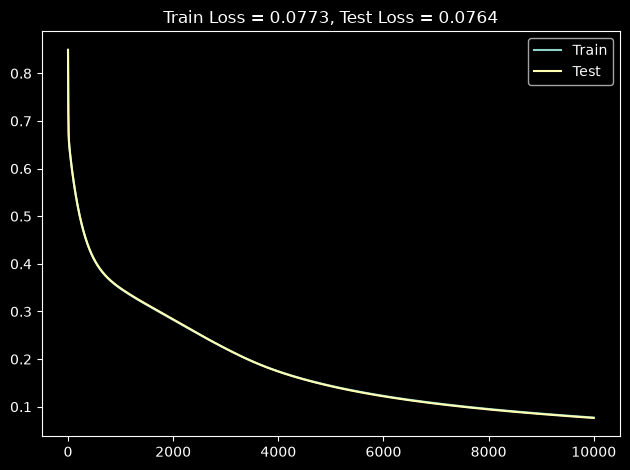

In [151]:
fig, ax = plt.subplots()
ax.plot(train_losses, label = 'Train')
ax.plot(test_losses, label = 'Test')
ax.set_title(f"Train Loss = {train_losses[-1]:.4f}, Test Loss = {test_losses[-1]:.4f}")
ax.legend()
fig.tight_layout()

### Measure Test Accuracy

In [152]:
logits = network_output(x_test, network)
predictions = (torch.sigmoid(logits) >= 0.5).float()
accuracy = (predictions == y_test).float().mean().item()
print(accuracy * 100, "%")

50.009626150131226 %
